In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from pygam import LinearGAM, s
import geopandas as gpd

In [20]:
grid = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Schildersbuurt/master_grid_schildersbuurt.gpkg",
    # layer="master_grid_with_features",
)
# Reproject to EPSG:28992 (RD New - meters) so calculations work properly
grid = grid.to_crs("EPSG:28992")

def determine_time_of_day(column_name):
    """
    Determine the time of day based on the hour in the given column.
    Returns a new column with the time of day categories.
    """
    # Check if it's an LST column
    if not column_name.startswith("LST_"):
        return None
    
    # Extract the time part after the space (e.g., '03:44')
    time_str = column_name.split(" ")[1]
    hour = int(time_str.split(":")[0])
    
    # Use the 6-hour blocks definition
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

lst_columns = [col for col in grid.columns if col.startswith("LST_")]

tod_dict = {"Night": [], "Morning": [], "Afternoon": [], "Evening": []}

for col in lst_columns:
    tod = determine_time_of_day(col)
    if tod:
        tod_dict[tod].append(col)

for tod, columns in tod_dict.items():
    if columns: 
        grid[f"LST_Mean_{tod}"] = grid[columns].mean(axis=1)
    else:
        grid[f"LST_Mean_{tod}"] = np.nan

grid.columns

Index(['grid_id', 'percentage_verharding', 'percentage_onverhard',
       'percentage_water', 'percentage_green_shadow', 'percentage_grey_shadow',
       'percentage_combined_shadow', 'boomkroonvolume_m3',
       'boomkroonoppervlakte_m2', 'biomassa_bermudez_kg',
       'LST_2025-06-02 13:54', 'LST_2025-06-02 15:30', 'LST_2025-06-03 13:05',
       'LST_2025-06-04 12:18', 'LST_2025-06-05 13:06', 'LST_2025-06-06 12:17',
       'LST_2025-06-09 11:29', 'LST_2025-06-11 11:29', 'LST_2025-06-12 09:04',
       'LST_2025-06-15 09:51', 'LST_2025-06-16 09:03', 'LST_2025-06-18 07:26',
       'LST_2025-06-29 04:58', 'LST_2025-06-30 04:10', 'LST_2025-07-10 22:26',
       'LST_2025-07-11 21:37', 'LST_2025-07-25 16:45', 'LST_2025-07-30 15:55',
       'LST_2025-08-06 11:52', 'LST_2025-08-09 12:39', 'LST_2025-08-10 11:50',
       'LST_2025-08-11 09:25', 'LST_2025-08-13 09:24', 'LST_2025-08-13 11:01',
       'LST_2025-08-14 10:12', 'LST_2025-08-15 07:47', 'LST_2025-08-19 06:10',
       'LST_2025-08-21 06

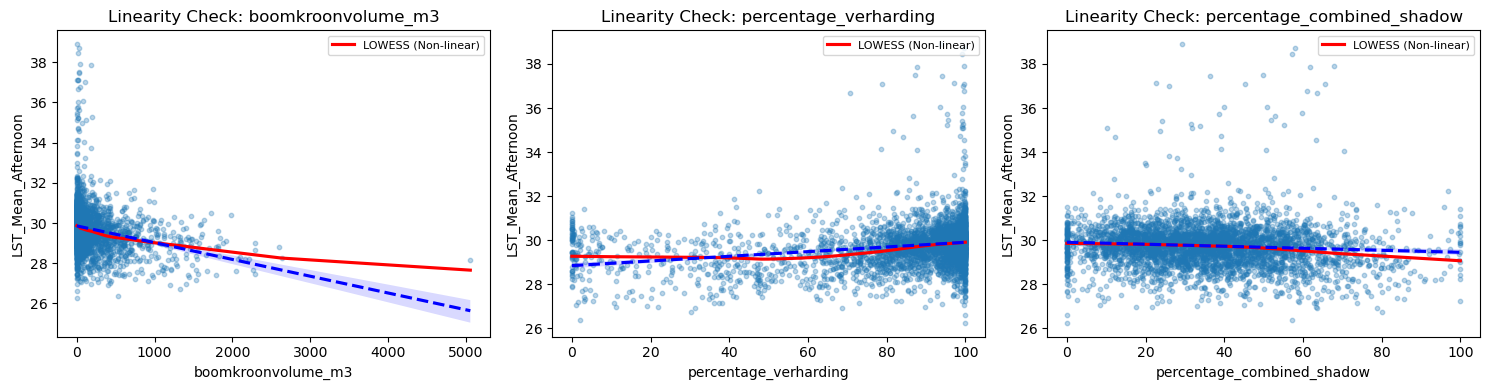

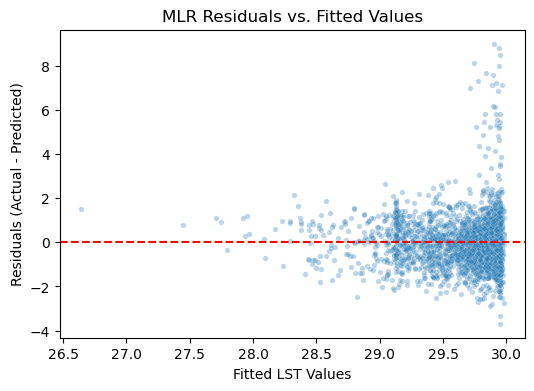

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     37.8466
Link Function:                     IdentityLink Log Likelihood:                                 -5430.4281
Number of Samples:                         3886 AIC:                                            10938.5493
                                                AICc:                                           10939.3542
                                                GCV:                                                0.9845
                                                Scale:                                              0.9835
                                                Pseudo R-Squared:                                   0.1107
Feature Function                  Lam

C:\Users\hoeks\AppData\Local\Temp\ipykernel_21396\1496721252.py:59: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


In [39]:


# Assuming df is your dataframe with columns: 
# ['tree_volume', 'pct_paved', 'pct_shadow', 'lst']
features = ['boomkroonvolume_m3', 'percentage_verharding', 'percentage_combined_shadow']

# ----------------------------------------------------------------
# 1. VISUAL CHECK: OLS vs. LOWESS (Locally Weighted Scatterplot Smoothing)
# ----------------------------------------------------------------
# If the straight line (Linear OLS) closely follows the curved line (LOWESS), 
# the relationship is linear. If they diverge (e.g., U-shapes or plateaus), it's non-linear.
plt.figure(figsize=(15, 4))
for i, feature in enumerate(features):
    plt.subplot(1, len(features), i + 1)
    sns.regplot(
        data=grid, x=feature, y='LST_Mean_Afternoon',  # Change to your target variable
        lowess=True,  # Calculates a non-linear local regression trend
        scatter_kws={'alpha': 0.3, 's': 10},
        line_kws={'color': 'red', 'label': 'LOWESS (Non-linear)'}
    )
    # Overlay standard OLS linear regression line for comparison
    sns.regplot(
        data=grid, x=feature, y='LST_Mean_Afternoon',  # Change to your target variable
        scatter=False, 
        line_kws={'color': 'blue', 'linestyle': '--', 'label': 'OLS (Linear)'}
    )
    plt.title(f'Linearity Check: {feature}')
    plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------
# 2. RESIDUAL PLOT CHECK: Residuals vs. Fitted Values
# ----------------------------------------------------------------
# Fit a standard Multiple Linear Regression (MLR) model
formula = 'LST_Mean_Afternoon ~ ' + ' + '.join(features)
mlr_model = ols(formula, data=grid).fit()

grid['fitted'] = mlr_model.fittedvalues
grid['residuals'] = mlr_model.resid

plt.figure(figsize=(6, 4))
sns.scatterplot(x='fitted', y='residuals', data=grid, alpha=0.3, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.title('MLR Residuals vs. Fitted Values')
plt.xlabel('Fitted LST Values')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()
# NOTE: If you see a distinct "U-shape" or curved pattern in these residuals, 
# it means MLR is missing non-linear trends, favoring a GAM.

# ----------------------------------------------------------------
# 3. QUANTITATIVE CHECK: GAM Estimated Degrees of Freedom (Egrid)
# ----------------------------------------------------------------
# Fit a GAM to see how much "bending" the data actually requires
X = grid[features].values
y = grid['LST_Mean_Afternoon'].values

gam = LinearGAM(s(0) + s(1) + s(2)).fit(X, y)

gam.summary()

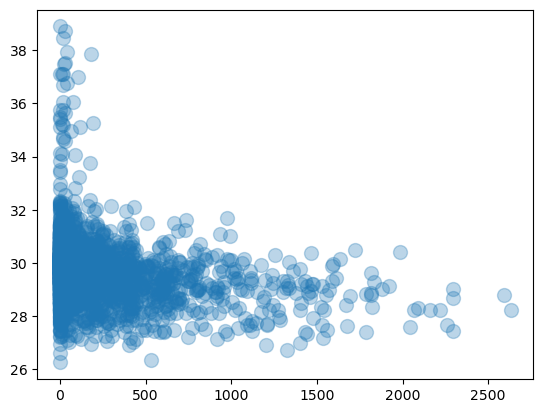

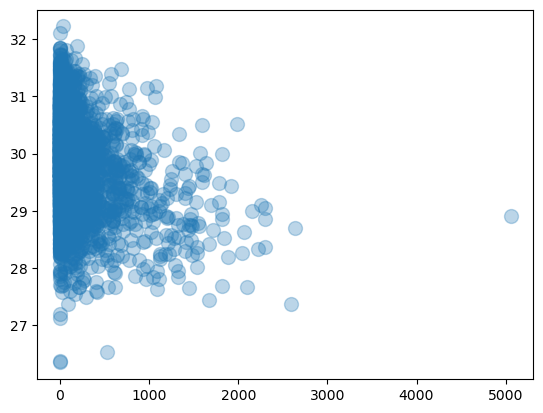

In [37]:
#remove outliers before plotting
# Remove outliers using the IQR method
outlier_columns = ["boomkroonvolume_m3", "LST_Mean_Afternoon"]
grid_no_outliers = grid.dropna(subset=outlier_columns).copy()

for column in outlier_columns:
    q1 = grid_no_outliers[column].quantile(0.25)
    q3 = grid_no_outliers[column].quantile(0.995)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    grid_no_outliers = grid_no_outliers[
        grid_no_outliers[column].between(lower_bound, upper_bound)
    ]

plt.plot(
    grid_no_outliers["boomkroonvolume_m3"],
    grid_no_outliers["LST_Mean_Afternoon"],
    "o",
    alpha=0.3,
    markersize=10,
)
plt.show()
plt.plot(grid['boomkroonvolume_m3'], grid['LST_Mean_Morning'], 'o', alpha=0.3, markersize=10)
plt.show()